**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
# Імпорт бібліотек
try:
    from google.colab import files
except ImportError:
    files = None

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")


**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Спосіб 1: якщо CSV уже завантажено в робочу папку Colab, він буде використаний.
# Щоб додати файл вручну: відкрийте ліву панель Files у Colab і завантажте
# diabetes_prediction_dataset.csv у кореневу папку сеансу.
csv_name = "diabetes_prediction_dataset.csv"
if os.path.exists(csv_name):
    print(f"Файл {csv_name} знайдено. Буде використано локальний CSV.")
else:
    print("Локальний CSV не знайдено. Наступна клітинка завантажить датасет онлайн.")


Локальний CSV не знайдено. Наступна клітинка завантажить датасет онлайн.


In [3]:
# Читаємо локальний CSV, якщо він був завантажений.
if os.path.exists(csv_name):
    df = pd.read_csv(csv_name)
    display(df.head())
else:
    print("Локальний CSV не знайдено; буде використано спосіб 2.")


Локальний CSV не знайдено; буде використано спосіб 2.


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
# Спосіб 2: отримання датасету з Kaggle через kagglehub.
# Якщо kagglehub або доступ до Kaggle недоступні, використовуємо публічну копію CSV.
if "df" not in globals():
    try:
        import kagglehub
        path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
        csv_path = os.path.join(path, "diabetes_prediction_dataset.csv")
        df = pd.read_csv(csv_path)
        print("Датасет завантажено через KaggleHub:", csv_path)
    except Exception as kaggle_error:
        print("KaggleHub недоступний, пробуємо завантажити CSV з відкритого дзеркала.")
        csv_url = "https://huggingface.co/datasets/GB2024/diabetes/resolve/main/diabetes_prediction_dataset.csv"
        df = pd.read_csv(csv_url)
        print("Датасет завантажено з відкритого дзеркала.")
else:
    print("Датасет уже завантажено способом 1.")


Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Датасет завантажено через KaggleHub: /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [5]:
# Перевіряємо, що датасет завантажено та він має очікувані стовпці.
required_columns = {
    "gender", "age", "hypertension", "heart_disease", "smoking_history",
    "bmi", "HbA1c_level", "blood_glucose_level", "diabetes"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"У датасеті відсутні потрібні стовпці: {sorted(missing_columns)}")
display(df.head())
print("Розмір датасету:", df.shape)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Розмір датасету: (100000, 9)


Вивести інформацію про датасет

In [6]:
# Інформація про структуру датасету
df.info()
print("\\nКількість рядків і стовпців:", df.shape)
print("\\nТипи даних:")
print(df.dtypes)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
\nКількість рядків і стовпців: (100000, 9)
\nТипи даних:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            fl

Провести дослідження категоріальних ознак

In [7]:
# Частоти категорій gender
print(df["gender"].value_counts(dropna=False))


gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [8]:
# Частоти категорій smoking_history
print(df["smoking_history"].value_counts(dropna=False))


smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [9]:
# Перегляд датасету
display(df)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [10]:
# Типи даних усіх стовпців
df.dtypes


,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# Кількість об'єктів кожного класу цільової змінної
df["diabetes"].value_counts().sort_index()


,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

За кількістю об'єктів класу 0 та класу 1 оцінюємо баланс. Якщо клас 0 значно переважає клас 1, вибірка є незбалансованою. Для цього датасету очікується суттєве переважання класу 0, тому під час навчання надалі застосовується SMOTE лише до train.

Перевірити наявність пропущених даних


In [12]:
# Кількість пропущених значень у кожному стовпці
df.isnull().sum()


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
# Кількість повністю однакових рядків
df.duplicated().sum()


np.int64(3854)

Видалити дублікати

In [14]:
# Видаляємо точні дублікати
df.drop_duplicates(inplace=True)
print("Розмір після видалення дублікатів:", df.shape)


Розмір після видалення дублікатів: (96146, 9)


In [15]:
# Перегляд очищеного датасету
display(df.head())


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [16]:
# Повторна перевірка розподілу цільової змінної після видалення дублікатів
df["diabetes"].value_counts().sort_index()


,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


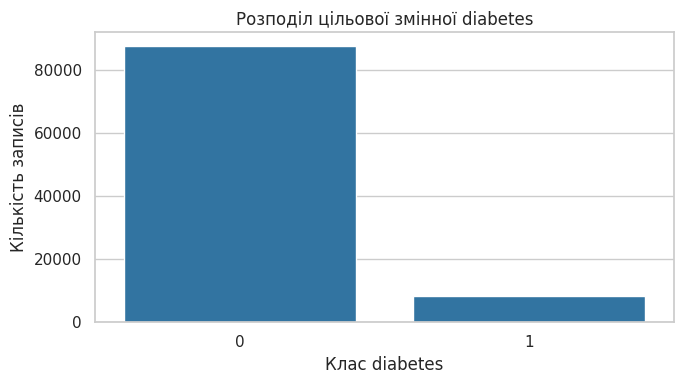

In [17]:
# Візуалізація балансу класів
plt.figure(figsize=(7, 4))
ax = sns.countplot(x="diabetes", data=df, color="tab:blue")
ax.set_title("Розподіл цільової змінної diabetes")
ax.set_xlabel("Клас diabetes")
ax.set_ylabel("Кількість записів")
plt.tight_layout()
plt.show()


Переглянути описові статистики **навчальної вибірки**

In [18]:
# Переконуємося, що пакет imbalanced-learn доступний у середовищі.
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from imblearn.over_sampling import SMOTE


In [19]:
# Відокремлюємо ознаки та цільову змінну
X = df.drop(columns=["diabetes"]).copy()
y = df["diabetes"].astype(int).copy()

# Поділ 80/20 зі збереженням пропорції класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\\nРозподіл класів у y_train:")
print(y_train.value_counts(normalize=True).sort_index())
print("\\nРозподіл класів у y_test:")
print(y_test.value_counts(normalize=True).sort_index())


X_train: (76916, 8) | X_test: (19230, 8)
\nРозподіл класів у y_train:
diabetes
0    0.911774
1    0.088226
Name: proportion, dtype: float64
\nРозподіл класів у y_test:
diabetes
0    0.911804
1    0.088196
Name: proportion, dtype: float64


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# Категоріальні стовпці кодуємо окремо після поділу.
categorical_cols = ["gender", "smoking_history"]

X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)

# Набір і порядок ознак у test приводимо до train.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Кількість ознак після кодування:", X_train.shape[1])
print("Однакові стовпці train/test:", list(X_train.columns) == list(X_test.columns))


Кількість ознак після кодування: 15
Однакові стовпці train/test: True


In [21]:
# Описові статистики навчальної вибірки
X_train.describe().T


,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# Кореляція ознак із цільовою змінною — тільки на train
train_with_target = X_train.copy()
train_with_target["diabetes"] = y_train
target_correlations = train_with_target.corr(numeric_only=True)["diabetes"].drop("diabetes")
target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index)


,diabetes
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_No Info,-0.113053
smoking_history_former,0.096162
gender_Male,0.040650
gender_Female,-0.040533


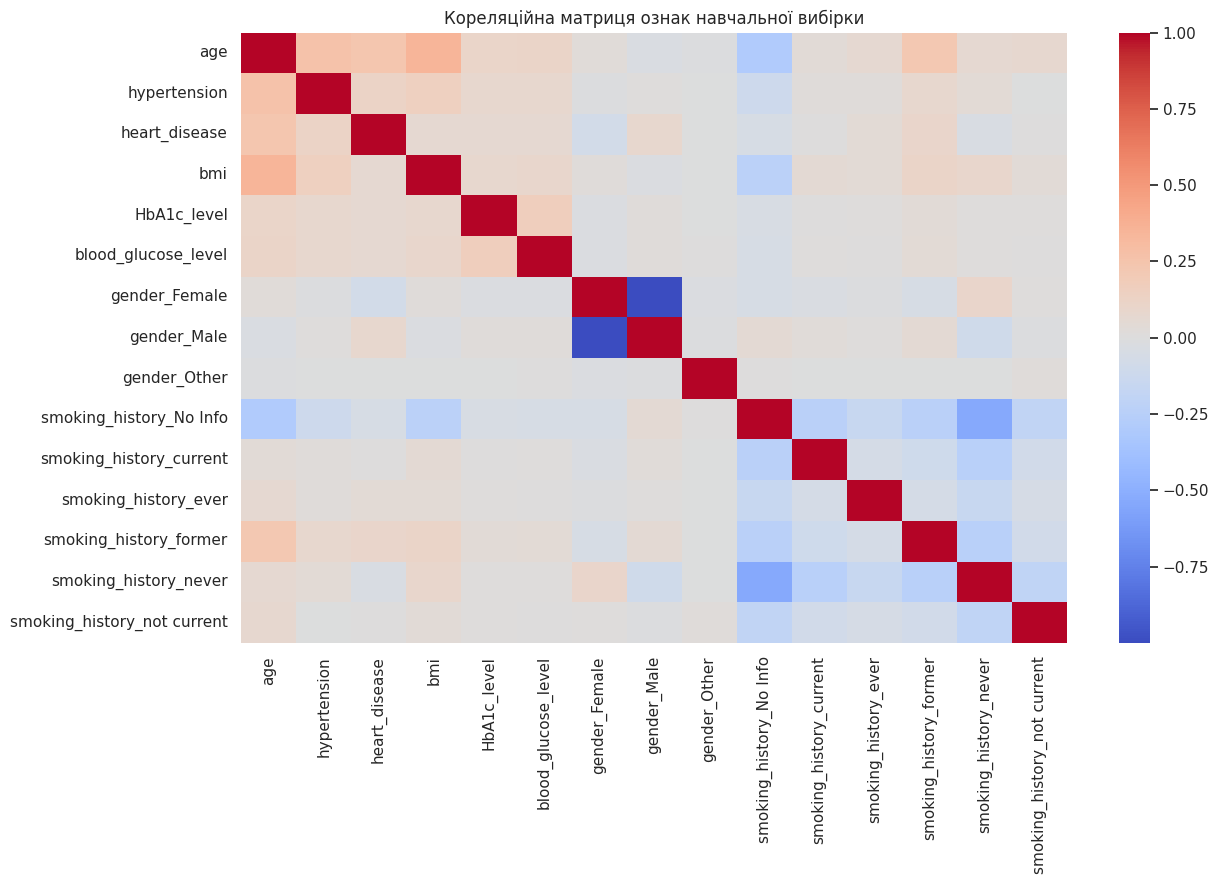

In [23]:
# Матриця кореляції ознак — тільки на X_train
feature_corr = X_train.corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(feature_corr, cmap="coolwarm", center=0, annot=False)
plt.title("Кореляційна матриця ознак навчальної вибірки")
plt.tight_layout()
plt.show()


**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

За результатами кореляційної матриці оцінюємо, чи є пари ознак із високою за модулем кореляцією. Сильна кореляція з цільовою змінною означає статистичний зв'язок, але не доводить причинність. Автоматично видаляти ознаки лише на підставі кореляції не потрібно: кожна ознака може містити корисну інформацію, а остаточне рішення має підтверджуватися якістю моделей на крос-валідації. Для висновків використовуються тільки навчальні дані.

Перевірити викиди **лише на навчальній вибірці**

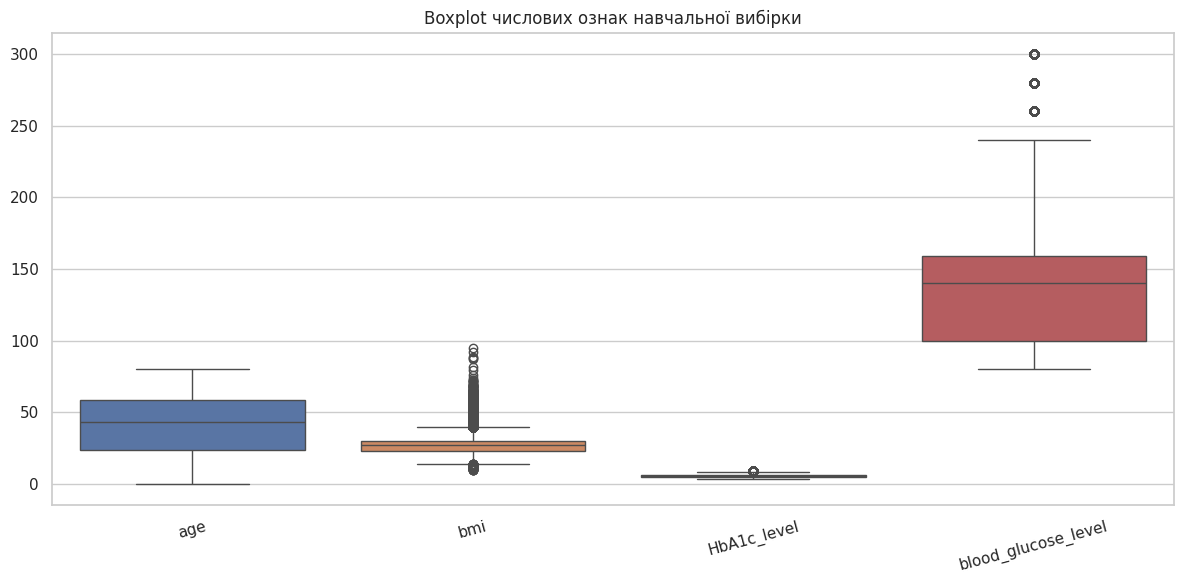

In [24]:
# Числові ознаки для аналізу викидів
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

# Boxplot будуємо лише для навчальної вибірки
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot числових ознак навчальної вибірки")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
#
# Приклад формул:
# q1 = X_train["bmi"].quantile(0.25)
# q3 = X_train["bmi"].quantile(0.75)
# iqr = q3 - q1
# lower = q1 - 1.5 * iqr
# upper = q3 + 1.5 * iqr


Перевірити асиметрію розподілів ознак **на train**

In [26]:
# Асиметрія розподілів числових ознак — тільки train
skewness = X_train[continuous_cols].skew().sort_values(ascending=False)
display(skewness.to_frame(name="Асиметрія"))


,Асиметрія
bmi,1.005016
blood_glucose_level,0.830778
HbA1c_level,-0.055651
age,-0.061461


In [27]:
# Перевірка пропусків окремо у train та test
print("Пропуски у X_train:")
display(X_train.isnull().sum().to_frame(name="Кількість"))
print("Пропуски у X_test:")
display(X_test.isnull().sum().to_frame(name="Кількість"))


Пропуски у X_train:


,Кількість
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


Пропуски у X_test:


,Кількість
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Після поділу даних аналіз показав дисбаланс цільових класів, який враховується під час навчання за допомогою SMOTE. Кореляції та викиди досліджувалися лише на X_train, щоб тестова вибірка не впливала на побудову моделі. Потенційні викиди не видалялися, оскільки високі значення глюкози та HbA1c можуть бути важливими для класифікації.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# Масштабування: параметри обчислюються тільки на train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір масштабованої train:", X_train_scaled.shape)
print("Розмір масштабованої test:", X_test_scaled.shape)


Розмір масштабованої train: (76916, 15)
Розмір масштабованої test: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# Балансуємо тільки навчальні дані
print("Класи до SMOTE:")
print(y_train.value_counts().sort_index())

smote = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("\\nКласи після SMOTE:")
print(pd.Series(y_train_balanced).value_counts().sort_index())
print("Розмір після балансування:", X_train_balanced.shape)


Класи до SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64
\nКласи після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64
Розмір після балансування: (140260, 15)


Оголошуємо моделі

In [30]:
# Чотири базові моделі
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1500, random_state=RANDOM_STATE
    ),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(
        max_iter=2000, tol=1e-3, random_state=RANDOM_STATE
    ),
    "SVC": SVC(kernel="linear", random_state=RANDOM_STATE, cache_size=1000)
}
print("Створено моделей:", list(models.keys()))


Створено моделей: ['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']


Навчити моделі, вивести матриці плутанини, класифікаційний звіт


\n===========================================================================
LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



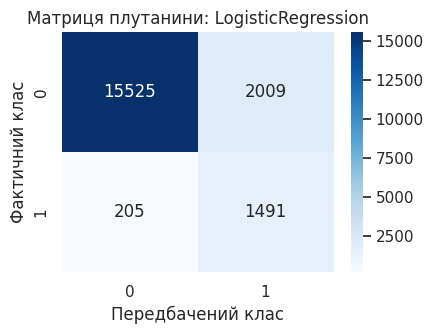

\n===========================================================================
RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



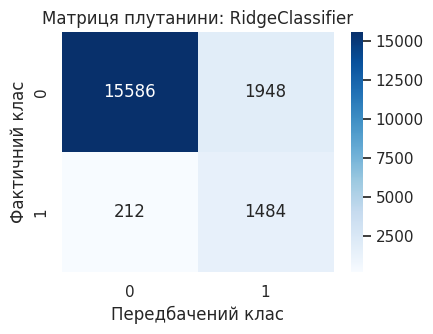

\n===========================================================================
SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



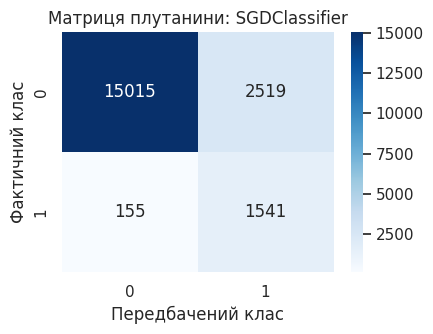

\n===========================================================================
SVC
SVC навчається на збалансованій підвибірці: 20000 записів.
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.41      0.89      0.56      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



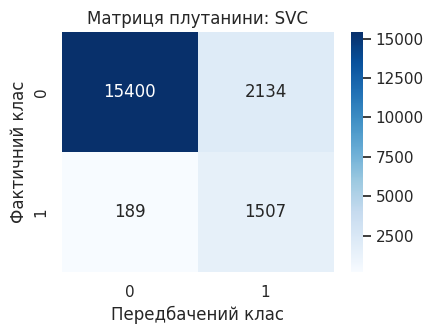

,F1
RidgeClassifier,0.578783
LogisticRegression,0.573903
SVC,0.564737
SGDClassifier,0.535441


In [31]:
# Навчання базових моделей та оцінювання на незмінній тестовій вибірці
base_models = {}
base_results = {}

for name, model in models.items():
    print("\\n" + "=" * 75)
    print(name)
    fit_X, fit_y = X_train_balanced, y_train_balanced
    if name == "SVC" and len(fit_y) > 20000:
        # SVC з ядром libsvm має високу обчислювальну складність.
        # Для нього беремо однакову кількість об'єктів кожного класу з уже збалансованого train.
        fit_y_array = np.asarray(fit_y)
        class_indices = [np.where(fit_y_array == cls)[0] for cls in np.unique(fit_y_array)]
        per_class = min(10000, min(len(idx) for idx in class_indices))
        selected = np.concatenate([
            np.random.RandomState(RANDOM_STATE).choice(idx, per_class, replace=False)
            for idx in class_indices
        ])
        fit_X = fit_X[selected]
        fit_y = fit_y_array[selected]
        print(f"SVC навчається на збалансованій підвибірці: {len(fit_y)} записів.")
    model.fit(fit_X, fit_y)
    y_pred = model.predict(X_test_scaled)

    base_models[name] = model
    base_results[name] = {
        "f1": f1_score(y_test, y_pred),
        "report": classification_report(y_test, y_pred, zero_division=0),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }

    print(classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame({
    name: {"F1": result["f1"]} for name, result in base_results.items()
}).T.sort_values("F1", ascending=False))


Оптимізувати гіперпараметри


In [32]:
# Компактні сітки параметрів для чотирьох моделей
param_grids = {
    "LogisticRegression": {
        "model__C": [0.1, 1.0, 5.0],
        "model__solver": ["liblinear"]
    },
    "RidgeClassifier": {
        "model__alpha": [0.1, 1.0, 10.0]
    },
    "SGDClassifier": {
        "model__loss": ["hinge", "log_loss"],
        "model__alpha": [0.0001, 0.001]
    },
    "SVC": {
        "model__C": [0.1, 1.0],
        "model__kernel": ["linear", "rbf"]
    }
}


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

\n================================================================================
Пошук параметрів: LogisticRegression
Найкращі параметри: {'model__C': 5.0, 'model__solver': 'liblinear'}
Середній F1 на крос-валідації: 0.6043
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



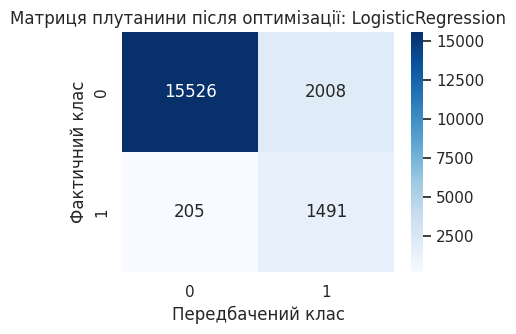

\n================================================================================
Пошук параметрів: RidgeClassifier
Найкращі параметри: {'model__alpha': 10.0}
Середній F1 на крос-валідації: 0.6516
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



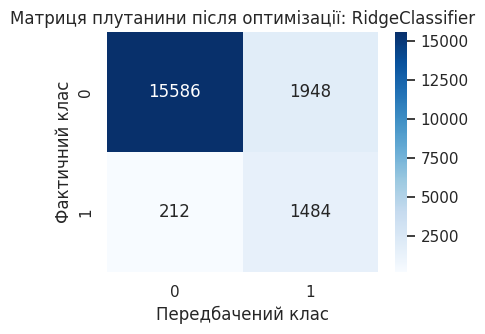

\n================================================================================
Пошук параметрів: SGDClassifier
Найкращі параметри: {'model__alpha': 0.0001, 'model__loss': 'log_loss'}
Середній F1 на крос-валідації: 0.6412
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



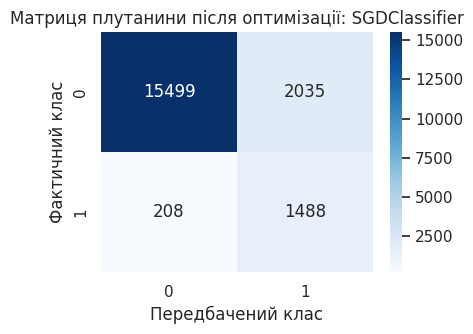

\n================================================================================
Пошук параметрів: SVC
Найкращі параметри: {'model__C': 0.1, 'model__kernel': 'linear'}
Середній F1 на крос-валідації: 0.6001
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



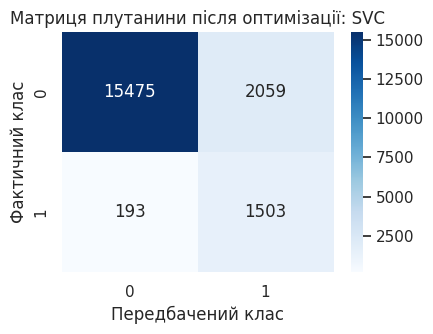

,Модель,Середній F1 (CV)
1,RidgeClassifier,0.651645
2,SGDClassifier,0.641178
0,LogisticRegression,0.604266
3,SVC,0.600072


In [34]:
# Пошук гіперпараметрів виконується тільки на X_train та y_train.
# StandardScaler і SMOTE знаходяться всередині Pipeline, тому застосовуються
# окремо в кожному навчальному згині крос-валідації.
from sklearn.base import clone

best_models = {}
best_scores = {}
search_objects = {}

for name, base_model in models.items():
    print("\\n" + "=" * 80)
    print("Пошук параметрів:", name)

    pipeline = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", clone(base_model))
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=300,
        max_resources=min(3000, len(X_train)),
        factor=3,
        n_jobs=1,
        verbose=0,
        random_state=RANDOM_STATE,
        error_score="raise"
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    search_objects[name] = search

    print("Найкращі параметри:", search.best_params_)
    print(f"Середній F1 на крос-валідації: {search.best_score_:.4f}")

    # Тестова вибірка використовується тільки для підсумкового оцінювання.
    tuned_pred = search.best_estimator_.predict(X_test)
    print(classification_report(y_test, tuned_pred, zero_division=0))

    cm = confusion_matrix(y_test, tuned_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини після оптимізації: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame({
    "Модель": list(best_scores.keys()),
    "Середній F1 (CV)": list(best_scores.values())
}).sort_values("Середній F1 (CV)", ascending=False))


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
# Найкраща модель визначається виключно за середнім F1 на крос-валідації
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print(f"Середній F1 на крос-валідації: {best_scores[best_model_name]:.4f}")


Найкраща модель: RidgeClassifier
Середній F1 на крос-валідації: 0.6516


In [36]:
# Випадково обираємо 10 індексів тестової вибірки
rng = np.random.RandomState(RANDOM_STATE)
sample_positions = rng.choice(len(X_test), size=min(10, len(X_test)), replace=False)

# best_model є Pipeline, тому передаємо початкові закодовані X_test,
# а масштабування виконується всередині Pipeline.
sample_X = X_test.iloc[sample_positions]
sample_true = y_test.iloc[sample_positions]
sample_pred = best_model.predict(sample_X)

comparison = pd.DataFrame({
    "Індекс": X_test.index[sample_positions],
    "Істинний клас": sample_true.to_numpy(),
    "Передбачений клас": sample_pred
})
display(comparison)


,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Відповіді за результатами виконання.**

1. Розподіл класів до SMOTE показує, наскільки рідше зустрічається клас `diabetes = 1`. Кореляції, асиметрія та потенційні викиди аналізувалися тільки на train. Викиди не видалялися.
2. Порівняння базових моделей і оптимізованих моделей наведено у звітах класифікації. Найкращу модель обрано за середнім F1 на трьох згинах крос-валідації, а не за тестовими показниками.
3. Оптимальні параметри кожної моделі виводяться під час HalvingGridSearchCV. У матриці плутанини помилки типу false negative — це випадки, коли реальний клас 1 передбачено як 0; false positive — коли реальний клас 0 передбачено як 1.
4. Відкладена тестова вибірка потрібна для незалежної оцінки узагальнювальної здатності моделі. Масштабування навчається тільки на train, а SMOTE застосовується тільки до train, щоб уникнути витоку інформації з тестових даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

Нижче наведено код додаткового завдання. Якщо якась із бібліотек відсутня, вона встановлюється автоматично.

\n===========================================================================
XGBoost
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     17534
           1       0.70      0.79      0.74      1696

    accuracy                           0.95     19230
   macro avg       0.84      0.88      0.86     19230
weighted avg       0.96      0.95      0.95     19230



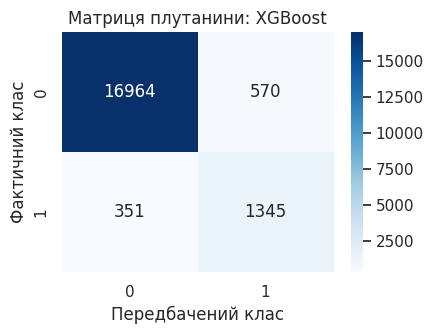

\n===========================================================================
LightGBM
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



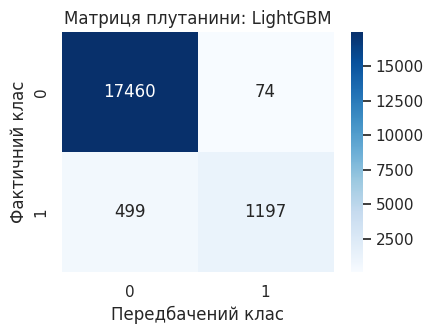

\n===========================================================================
CatBoost
              precision    recall  f1-score   support

           0       0.98      0.95      0.97     17534
           1       0.61      0.82      0.70      1696

    accuracy                           0.94     19230
   macro avg       0.79      0.89      0.83     19230
weighted avg       0.95      0.94      0.94     19230



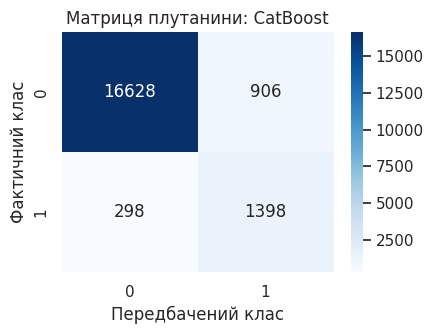

,precision_1,recall_1,f1_1,accuracy
LightGBM,0.941778,0.705778,0.806876,0.970203
XGBoost,0.702350,0.793042,0.744946,0.952106
CatBoost,0.606771,0.824292,0.699000,0.937389


Висновок: порівняйте F1 та recall для класу 1. Для задачі виявлення діабету
особливо важливо враховувати recall, оскільки false negative означає пропущений позитивний випадок.
\nПІДСУМОК ЛАБОРАТОРНОЇ РОБОТИ
Кількість записів після видалення дублікатів: 96146
Клас 0: 87664; клас 1: 8482
Найкраща з чотирьох основних моделей за CV F1: RidgeClassifier (F1=0.6516).
Її оптимальні параметри: {'model__alpha': 10.0}
Найкраща додаткова модель за F1 класу 1: LightGBM (F1=0.8069, Recall=0.7058).
Test не використовувався для масштабування, SMOTE або вибору гіперпараметрів.


In [37]:
# Додаткові моделі: XGBoost, LightGBM та CatBoost
import importlib.util
import subprocess
import sys

optional_packages = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost"
}
for module_name, package_name in optional_packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    "XGBoost": XGBClassifier(
        n_estimators=80, max_depth=5, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.85,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=80, learning_rate=0.08, num_leaves=31,
        random_state=RANDOM_STATE, verbosity=-1, n_jobs=1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=80, depth=5, learning_rate=0.08,
        random_seed=RANDOM_STATE, verbose=False, thread_count=1
    )
}

extra_results = {}
for name, model in extra_models.items():
    print("\\n" + "=" * 75)
    print(name)
    model.fit(X_train_balanced, y_train_balanced)
    prediction = model.predict(X_test_scaled)
    prediction = np.asarray(prediction).reshape(-1).astype(int)

    report = classification_report(y_test, prediction, output_dict=True, zero_division=0)
    extra_results[name] = {
        "precision_1": report["1"]["precision"],
        "recall_1": report["1"]["recall"],
        "f1_1": report["1"]["f1-score"],
        "accuracy": report["accuracy"]
    }

    print(classification_report(y_test, prediction, zero_division=0))
    cm = confusion_matrix(y_test, prediction)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.tight_layout()
    plt.show()

extra_results_df = pd.DataFrame(extra_results).T.sort_values("f1_1", ascending=False)
display(extra_results_df)

print("Висновок: порівняйте F1 та recall для класу 1. Для задачі виявлення діабету")
print("особливо важливо враховувати recall, оскільки false negative означає пропущений позитивний випадок.")


# Підсумковий автоматично сформований результат за поточним датасетом
class_counts = df["diabetes"].value_counts().sort_index()
print("\\nПІДСУМОК ЛАБОРАТОРНОЇ РОБОТИ")
print(f"Кількість записів після видалення дублікатів: {len(df)}")
print(f"Клас 0: {class_counts.get(0, 0)}; клас 1: {class_counts.get(1, 0)}")
print(f"Найкраща з чотирьох основних моделей за CV F1: {best_model_name} "
      f"(F1={best_scores[best_model_name]:.4f}).")
best_params = search_objects[best_model_name].best_params_
print("Її оптимальні параметри:", best_params)
if "extra_results_df" in globals() and not extra_results_df.empty:
    print("Найкраща додаткова модель за F1 класу 1:", extra_results_df.index[0],
          f"(F1={extra_results_df.iloc[0]['f1_1']:.4f}, "
          f"Recall={extra_results_df.iloc[0]['recall_1']:.4f}).")
print("Test не використовувався для масштабування, SMOTE або вибору гіперпараметрів.")
